# Measuring  VQCs 


**What the paper measures:** classification **accuracy** of different VQC circuits on a binary classification task.

| Step | Paper | This notebook |
|---|---|---|
| Train | Normal (one-chip) circuit, **no noise**, cross-entropy loss | Same (COBYLA optimizer) |
| Validation accuracy | Tracked during training | Same |
| Test 1: ideal | Normal circuit, no noise | Same |
| Test 2: distributed + noise | Circuit split over QPUs, every CX between QPUs replaced by the **remote-CX protocol**, depolarizing noise p = 0.03 | Same |
| Setup | 8 qubits on 4 QPUs, 10 layers, 3 datasets | Smaller: 4 qubits on **2 QPUs**, 3 layers, 3 datasets |

We compare our two circuits:
- **Original**: Ry(x) → CX(0,1) → CX(1,2) (remote) → CX(2,3) → Ry(θ)
- **H variation**: same, but with an H gate on the control qubit before every CX

In [1]:
# Install dependencies
%pip install --quiet "qiskit[visualization]" qiskit-aer scikit-learn scipy pandas
from qiskit import QuantumCircuit
import numpy as np

Note: you may need to restart the kernel to use updated packages.


## 1. Settings

In [ ]:
n = 4             # data qubits (the qubits the VQC actually uses)
layers = 3        # how many times we repeat (CX chain + Ry(theta)); 
noise_p = 0.03    # depolarizing noise probability 
shots = 1000      # shots for the noisy test 
max_iter = 150    # optimizer iterations 
# How qubits are placed on 2 QPUs 
#   QPU 0: qubits 0,1 = data   qubits 2,3 = communication
#   QPU 1: qubits 4,5 = data   qubits 6,7 = communication
data_qubits = [0, 1, 4, 5]   # logical qubit i lives on physical qubit data_qubits[i]
comm0 = 2                    # communication qubit on QPU 0
comm1 = 6                    # communication qubit on QPU 1

## 2. The remote-CX protocol Fig. 1 

A CX between qubits on **different QPUs** can't be done directly. Instead:
1. Make a Bell pair between one communication qubit on each QPU (H + CX)
2. CX from the control to its local comm qubit, then measure it → apply X on the other comm qubit
3. CX from that comm qubit to the target
4. H on that comm qubit, measure it → apply Z on the control



In [3]:
def remote_cx(qc, control, target):
    qc.h(comm0)               # 1) make a Bell pair between the two QPUs
    qc.cx(comm0, comm1)
    qc.cx(control, comm0)     # 2) control -> its local comm qubit
    qc.cx(comm0, comm1)       #    (measure comm0, X on comm1 if 1)
    qc.cx(comm1, target)      # 3) comm qubit on the other QPU -> target
    qc.h(comm1)               # 4) (measure comm1, Z on control if 1)
    qc.cz(comm1, control)
    qc.reset(comm0)           # free the comm qubits for the next remote-CX
    qc.reset(comm1)

## 3. Build the VQC

`use_h=True` gives the H variation. `distributed=True` builds the 8-qubit, 2-QPU version where CX(1,2) becomes a remote-CX.

In [5]:
def build_vqc(x, theta, use_h=False, distributed=False):
    if distributed:
        qc = QuantumCircuit(8)
        q = data_qubits
    else:
        qc = QuantumCircuit(n)
        q = [0, 1, 2, 3]

    # Encoding layer: Ry(x_i)
    for i in range(n):
        qc.ry(x[i], q[i])

    k = 0  # counts which theta we are on
    for layer in range(layers):
        # Entangling: CX(0,1), CX(1,2), CX(2,3)
        for a in range(n - 1):
            b = a + 1
            if use_h:
                qc.h(q[a])                    # the H variation
            if distributed and a == 1:        # CX(1,2) crosses QPU 0 -> QPU 1
                remote_cx(qc, q[a], q[b])
            else:
                qc.cx(q[a], q[b])
        # Trainable layer: Ry(theta_i)
        for i in range(n):
            qc.ry(theta[k], q[i])
            k += 1
    return qc

n_params = n * layers
print("Trainable parameters:", n_params)

Trainable parameters: 12


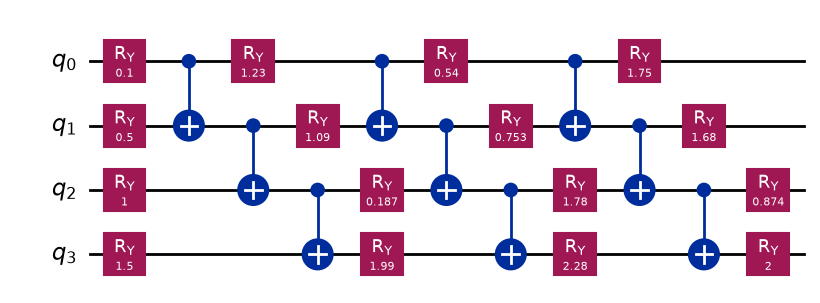

In [6]:
x_demo = [0.1, 0.5, 1.0, 1.5]
theta_demo = np.random.uniform(0, np.pi, n_params)

build_vqc(x_demo, theta_demo, use_h=False).draw("mpl", fold=-1)

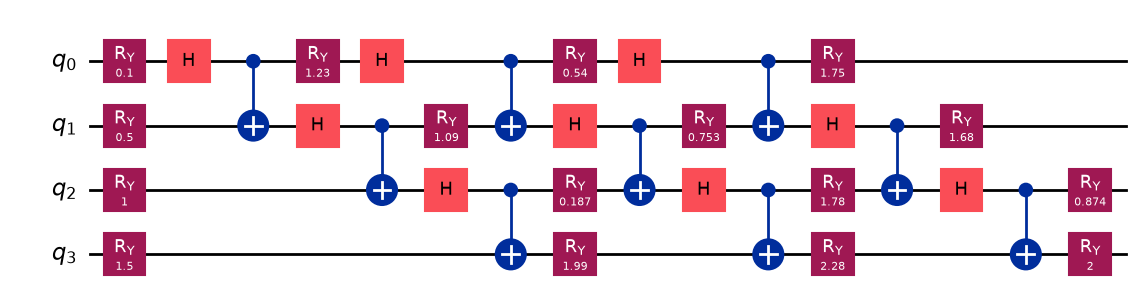

In [7]:
build_vqc(x_demo, theta_demo, use_h=True).draw("mpl", fold=-1)

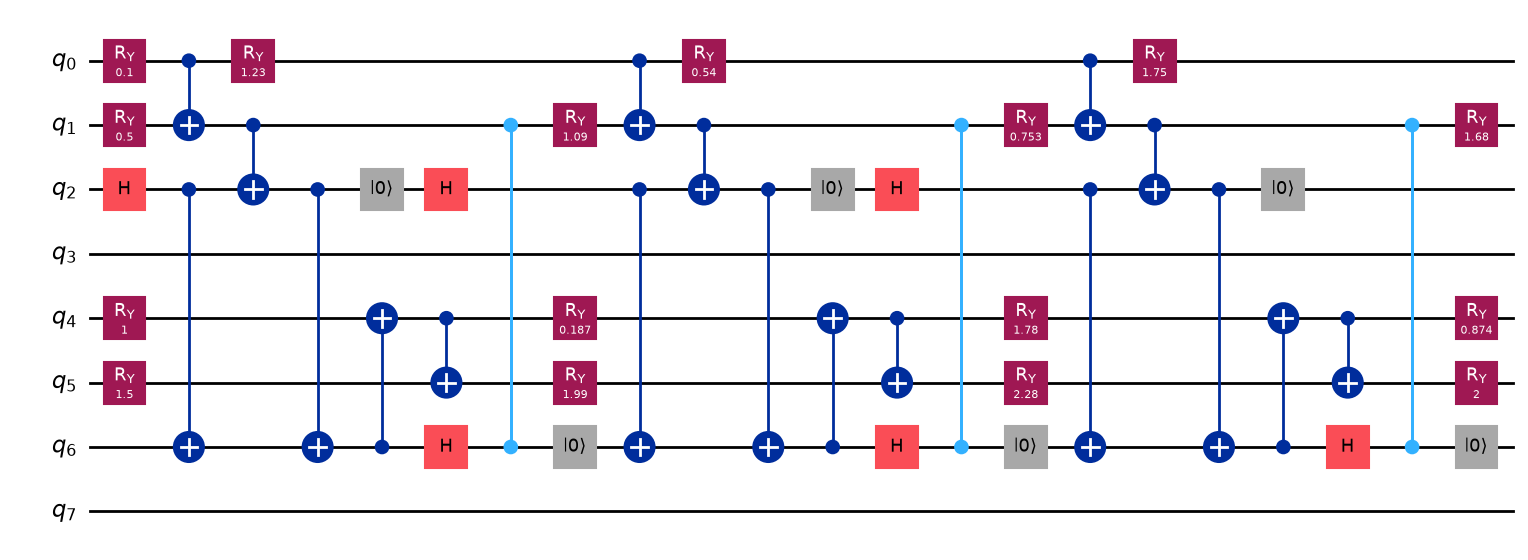

In [8]:
# Distributed version of the original circuit (8 qubits, 2 QPUs)
build_vqc(x_demo, theta_demo, use_h=False, distributed=True).draw("mpl", fold=-1)

**Sanity check:** without noise, the distributed circuit should give the same answer as the normal one.

In [9]:
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace

normal = Statevector(build_vqc(x_demo, theta_demo, use_h=True)).probabilities([0, 1])
dist_rho = DensityMatrix(build_vqc(x_demo, theta_demo, use_h=True, distributed=True))
dist = dist_rho.probabilities([0, 1])   # physical qubits 0,1 = data qubits 0,1

print("normal     :", np.round(normal, 4))
print("distributed:", np.round(dist, 4))

normal     : [0.1837 0.6609 0.0465 0.1089]
distributed: [0.1837 0.6609 0.0465 0.1089]


## 4. Turning the circuit into a classifier (Eq. 1–6 in the paper)

- Measure ⟨Z⟩ on qubit 0 and qubit 1 → two numbers
- Softmax → probability of class 0 and class 1
- Loss = cross-entropy

In [ ]:
from qiskit.quantum_info import SparsePauliOp

Z0 = SparsePauliOp("IIIZ")   # Z on qubit 0 (Qiskit reads qubits right to left)
Z1 = SparsePauliOp("IIZI")   # Z on qubit 1

def softmax(z):
    e = np.exp(z)
    return e / e.sum()

def predict_proba(x, theta, use_h):
    state = Statevector(build_vqc(x, theta, use_h))
    z = [state.expectation_value(Z0).real, state.expectation_value(Z1).real]
    return softmax(np.array(z))

def accuracy(theta, X, y, use_h):
    preds = [np.argmax(predict_proba(x, theta, use_h)) for x in X]
    return np.mean(np.array(preds) == y)

def loss(theta, X, y, use_h):
    total = 0
    for x, label in zip(X, y):
        p = predict_proba(x, theta, use_h)
        total += -np.log(p[label] + 1e-10)
    return total / len(X)

## 5. Noisy distributed test

Depolarizing error (p = 0.03) on every gate, then run the 8-qubit distributed circuit with 1000 shots.
We get ⟨Z⟩ from the counts: ⟨Z⟩ = P(0) − P(1).

In [10]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit import transpile

noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(noise_p, 1), ["ry", "h"])
noise_model.add_all_qubit_quantum_error(depolarizing_error(noise_p, 2), ["cx", "cz"])
noisy_sim = AerSimulator(noise_model=noise_model)

def noisy_distributed_accuracy(theta, X, y, use_h):
    circuits = []
    for x in X:
        qc = QuantumCircuit(8, 2)
        qc.compose(build_vqc(x, theta, use_h, distributed=True), inplace=True)
        qc.measure([0, 1], [0, 1])       # data qubits 0 and 1
        circuits.append(qc)

    circuits_t = transpile(circuits, noisy_sim, optimization_level=0)
    results = noisy_sim.run(circuits_t, shots=shots).result()

    correct = 0
    for i in range(len(X)):
        counts = results.get_counts(i)
        z0 = 0
        z1 = 0
        for bits, c in counts.items():     # bits look like "10" -> qubit1 qubit0
            z0 += c if bits[-1] == "0" else -c
            z1 += c if bits[-2] == "0" else -c
        pred = np.argmax(softmax(np.array([z0, z1]) / shots))
        correct += (pred == y[i])
    return correct / len(X)

## 6. Datasets

Like the paper: 3 binary classification datasets made with scikit-learn, split 70% train / 15% validation / 15% test.
Features are scaled to [0, π] so they can be used as Ry angles.

In [11]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

def make_dataset(seed):
    X, y = make_classification(n_samples=300, n_features=4, n_informative=4,
                               n_redundant=0, random_state=seed)
    X = MinMaxScaler((0, np.pi)).fit_transform(X)
    X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.3, random_state=seed)
    X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=seed)
    return X_train, y_train, X_val, y_val, X_test, y_test

## 7. Run the experiment

For each dataset and each circuit: train (no noise), track validation accuracy, then test ideal and test distributed + noisy.
This takes a few minutes.

In [12]:
from scipy.optimize import minimize
import time

circuits = {"Original": False, "H variation": True}
results = []       # final numbers
val_curves = {}    # validation accuracy during training

for ds in range(3):
    X_train, y_train, X_val, y_val, X_test, y_test = make_dataset(ds)

    for name, use_h in circuits.items():
        start = time.time()
        curve = []
        step = [0]

        def cost(theta):
            step[0] += 1
            if step[0] % 10 == 0:            # every 10 steps, check validation accuracy
                curve.append(accuracy(theta, X_val, y_val, use_h))
            return loss(theta, X_train, y_train, use_h)

        theta0 = np.random.default_rng(0).uniform(0, 2 * np.pi, n_params)
        res = minimize(cost, theta0, method="COBYLA", options={"maxiter": max_iter})
        theta = res.x

        row = {
            "dataset": ds + 1,
            "circuit": name,
            "val acc": accuracy(theta, X_val, y_val, use_h),
            "test acc (ideal)": accuracy(theta, X_test, y_test, use_h),
            "test acc (distributed + noise)": noisy_distributed_accuracy(theta, X_test, y_test, use_h),
        }
        results.append(row)
        val_curves[(ds + 1, name)] = curve
        print(row, f"({time.time() - start:.0f}s)")

{'dataset': 1, 'circuit': 'Original', 'val acc': np.float64(0.7111111111111111), 'test acc (ideal)': np.float64(0.7333333333333333), 'test acc (distributed + noise)': np.float64(0.6666666666666666)} (61s)


{'dataset': 1, 'circuit': 'H variation', 'val acc': np.float64(0.7555555555555555), 'test acc (ideal)': np.float64(0.6666666666666666), 'test acc (distributed + noise)': np.float64(0.6666666666666666)} (75s)


{'dataset': 2, 'circuit': 'Original', 'val acc': np.float64(0.7333333333333333), 'test acc (ideal)': np.float64(0.7777777777777778), 'test acc (distributed + noise)': np.float64(0.8)} (60s)


{'dataset': 2, 'circuit': 'H variation', 'val acc': np.float64(0.7111111111111111), 'test acc (ideal)': np.float64(0.7777777777777778), 'test acc (distributed + noise)': np.float64(0.8222222222222222)} (73s)


{'dataset': 3, 'circuit': 'Original', 'val acc': np.float64(0.7777777777777778), 'test acc (ideal)': np.float64(0.5555555555555556), 'test acc (distributed + noise)': np.float64(0.6)} (62s)


{'dataset': 3, 'circuit': 'H variation', 'val acc': np.float64(0.6888888888888889), 'test acc (ideal)': np.float64(0.5777777777777777), 'test acc (distributed + noise)': np.float64(0.6)} (75s)


## 8. Results

In [13]:
import pandas as pd

df = pd.DataFrame(results)
df["drop from noise"] = df["test acc (ideal)"] - df["test acc (distributed + noise)"]
df.round(3)

,dataset,circuit,val acc,test acc (ideal),test acc (distributed + noise),drop from noise
0,1,Original,0.711,0.733,0.667,0.067
1,1,H variation,0.756,0.667,0.667,0.000
2,2,Original,0.733,0.778,0.800,-0.022
3,2,H variation,0.711,0.778,0.822,-0.044
4,3,Original,0.778,0.556,0.600,-0.044
5,3,H variation,0.689,0.578,0.600,-0.022


In [14]:
# Average over the 3 datasets
df.groupby("circuit")[["val acc", "test acc (ideal)", "test acc (distributed + noise)", "drop from noise"]].mean().round(3)

,val acc,test acc (ideal),test acc (distributed + noise),drop from noise
circuit,,,,
H variation,0.719,0.674,0.696,-0.022
Original,0.741,0.689,0.689,0.000


In [15]:
# Cost of each circuit when distributed: gate counts, depth, remote-CX count
theta_any = np.zeros(n_params)
for name, use_h in circuits.items():
    qc = build_vqc(x_demo, theta_any, use_h, distributed=True)
    ops = qc.count_ops()
    print(f"{name:12s} depth={qc.depth():3d}  gates={dict(ops)}  remote-CX={layers}")

Original     depth= 22  gates={'cx': 18, 'ry': 16, 'h': 6, 'reset': 6, 'cz': 3}  remote-CX=3
H variation  depth= 26  gates={'cx': 18, 'ry': 16, 'h': 15, 'reset': 6, 'cz': 3}  remote-CX=3


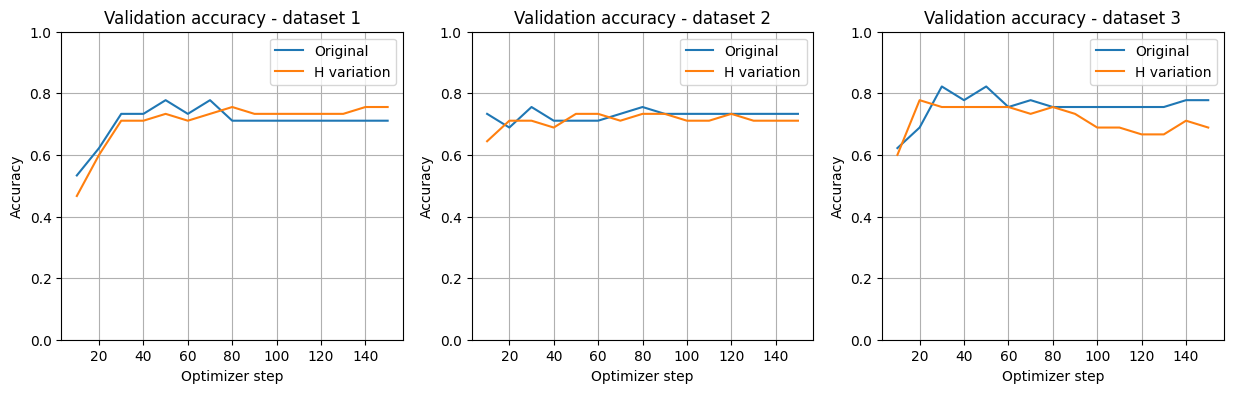

In [16]:
import matplotlib.pyplot as plt

# Validation accuracy during training (like Fig. 4 left in the paper)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ds in range(3):
    ax = axes[ds]
    for name in circuits:
        curve = val_curves[(ds + 1, name)]
        ax.plot(np.arange(1, len(curve) + 1) * 10, curve, label=name)
    ax.set_title(f"Validation accuracy - dataset {ds + 1}")
    ax.set_xlabel("Optimizer step")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()
plt.show()

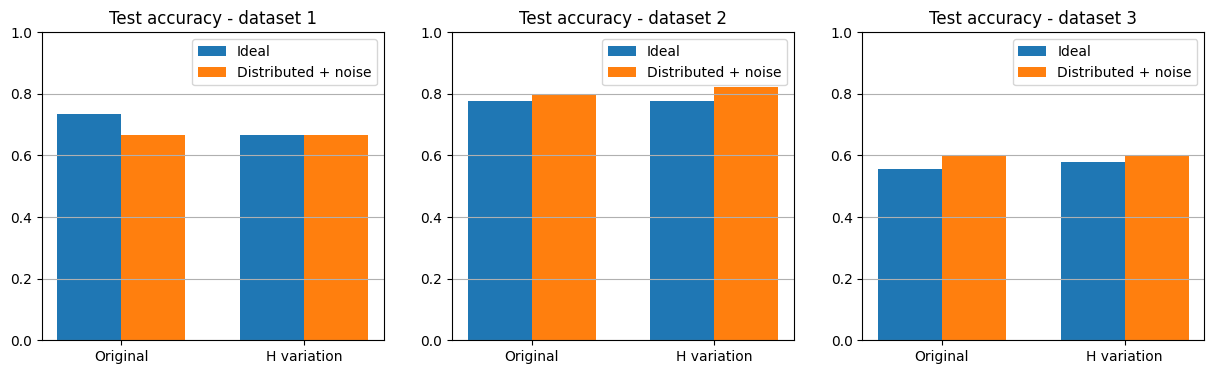

In [17]:
# Test accuracy: ideal vs distributed + noise (like Fig. 4 right / Fig. 5)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
width = 0.35
for ds in range(3):
    ax = axes[ds]
    sub = df[df["dataset"] == ds + 1]
    pos = np.arange(len(sub))
    ax.bar(pos - width / 2, sub["test acc (ideal)"], width, label="Ideal")
    ax.bar(pos + width / 2, sub["test acc (distributed + noise)"], width, label="Distributed + noise")
    ax.set_xticks(pos)
    ax.set_xticklabels(sub["circuit"])
    ax.set_title(f"Test accuracy - dataset {ds + 1}")
    ax.set_ylim(0, 1)
    ax.grid(True, axis="y")
    ax.legend()
plt.show()

## 9. What we found

Averaged over the 3 datasets:

| Circuit | Val acc | Test acc (ideal) | Test acc (distributed + noise) |
|---|---|---|---|
| Original | 0.74 | 0.69 | 0.69 |
| H variation | 0.72 | 0.67 | 0.70 |

- **Both circuits score about the same.** Each test set has 45 samples, so one sample is about 2%. Every difference here is within 1–2 samples, which is too small to say either circuit is better.
- **Noise barely hurt either circuit.** Both use the same number of remote-CX gates (1 per layer = 3 total), and those gates are where most of the extra noise comes from. The paper found the same thing: circuits with **fewer** remote-CX gates hold up better under noise.
- **The H gates cost something.** They add 9 extra gates and make the distributed circuit deeper (26 vs 22) without improving accuracy.

To make the comparison more like the paper, try `layers = 10`, `max_iter = 1000`, and several random seeds per dataset (it will take much longer).
